In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt

from torchvision import models, transforms
from torch.utils.data import DataLoader

from medmnist.dataset import PneumoniaMNIST

In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [3]:
weighted_model = models.resnet18(weights=None)

weighted_model.fc = nn.Linear(
    weighted_model.fc.in_features,
    2
)

weighted_model = weighted_model.to(device)

In [4]:
model_path = "../results/resnet18_weighted.pth"

weighted_model.load_state_dict(
    torch.load(
        model_path,
        map_location=device
    )
)

weighted_model.eval()

print("Weighted ResNet-18 loaded successfully.")

Weighted ResNet-18 loaded successfully.


In [5]:
resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor()
])

In [6]:
test_dataset_resnet = PneumoniaMNIST(
    split="test",
    transform=resnet_transform,
    download=True
)

test_loader_resnet = DataLoader(
    test_dataset_resnet,
    batch_size=32,
    shuffle=False
)

print("Test samples:", len(test_dataset_resnet))

Test samples: 624


In [7]:
image, label = test_dataset_resnet[0]

print("Image shape:", image.shape)
print("Label:", int(label))

Image shape: torch.Size([3, 224, 224])
Label: 1


C:\Users\Yash pal\AppData\Local\Temp\ipykernel_9384\3183023873.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("Label:", int(label))


# Grad-CAM implementation

In [8]:
activations = None
gradients = None

In [9]:
# Forward and backward hooks

def forward_hook(module, input, output):
    global activations
    activations = output


def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

In [10]:
target_layer = weighted_model.layer4[-1].conv2

forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

In [11]:
# Grad-CAM Function

def generate_gradcam(model, image, target_class):

    global activations, gradients

    # Clear previous gradients
    model.zero_grad()

    # Forward pass
    output = model(image)

    # Select target class score
    target_score = output[:, target_class]

    # Backward pass
    target_score.backward()

    # Get feature maps and gradients
    activation = activations
    gradient = gradients

    # Calculate importance weights
    weights = gradient.mean(
        dim=(2, 3),
        keepdim=True
    )

    # Weighted combination of feature maps
    cam = (weights * activation).sum(
        dim=1,
        keepdim=True
    )

    # Keep positive contributions
    cam = F.relu(cam)

    # Resize CAM to input image size
    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    # Remove batch/channel dimensions
    cam = cam.squeeze().detach().cpu().numpy()

    # Normalize between 0 and 1
    cam = cam - cam.min()

    if cam.max() != 0:
        cam = cam / cam.max()

    return cam

In [12]:
image, label = test_dataset_resnet[0]

image_batch = image.unsqueeze(0).to(device)

print("Image batch shape:", image_batch.shape)
print("Actual label:", int(label))

Image batch shape: torch.Size([1, 3, 224, 224])
Actual label: 1


C:\Users\Yash pal\AppData\Local\Temp\ipykernel_9384\578591650.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("Actual label:", int(label))


In [13]:
weighted_model.eval()

output = weighted_model(image_batch)

probabilities = torch.softmax(
    output,
    dim=1
)

pneumonia_probability = probabilities[0, 1].item()

best_threshold = 0.80

predicted_class = (
    1
    if pneumonia_probability >= best_threshold
    else 0
)

print("Actual class:", int(label))
print(
    f"Pneumonia probability: "
    f"{pneumonia_probability:.4f}"
)
print("Predicted class:", predicted_class)

Actual class: 1
Pneumonia probability: 1.0000
Predicted class: 1


C:\Users\Yash pal\AppData\Local\Temp\ipykernel_9384\3466425874.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("Actual class:", int(label))


In [14]:
cam = generate_gradcam(
    weighted_model,
    image_batch,
    predicted_class
)

print("CAM shape:", cam.shape)
print("CAM minimum:", cam.min())
print("CAM maximum:", cam.max())

CAM shape: (224, 224)
CAM minimum: 0.0
CAM maximum: 1.0


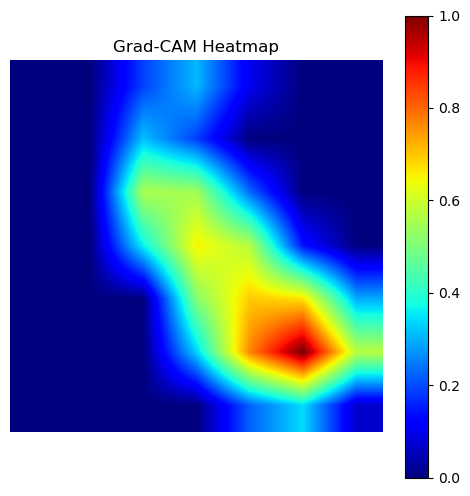

In [16]:
plt.figure(figsize=(6, 6))

plt.imshow(
    cam,
    cmap="jet"
)

plt.colorbar()

plt.title("Grad-CAM Heatmap")

plt.axis("off")

plt.savefig("../plots/gradcam_heatmap.png")

plt.show()

C:\Users\Yash pal\AppData\Local\Temp\ipykernel_9384\3667276502.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f"Actual: {int(label)} | "


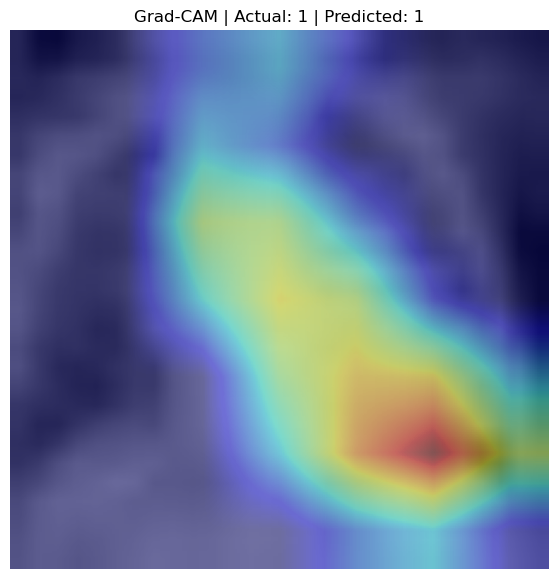

In [17]:
original_image = image.permute(
    1, 2, 0
).numpy()

plt.figure(figsize=(7, 7))

plt.imshow(original_image)

plt.imshow(
    cam,
    cmap="jet",
    alpha=0.4
)

plt.title(
    f"Grad-CAM | "
    f"Actual: {int(label)} | "
    f"Predicted: {predicted_class}"
)

plt.axis("off")

plt.savefig("../plots/overly_gradcam_on_Xray.png")

plt.show()

In [18]:
# Find True Positive samples

weighted_model.eval()

true_positive_indices = []

best_threshold = 0.80

for idx in range(len(test_dataset_resnet)):

    image, label = test_dataset_resnet[idx]

    image_batch = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = weighted_model(image_batch)

        probabilities = torch.softmax(output, dim=1)

        pneumonia_probability = probabilities[0, 1].item()

    predicted_class = (
        1 if pneumonia_probability >= best_threshold else 0
    )

    actual_class = int(label)

    # True Positive condition
    if actual_class == 1 and predicted_class == 1:
        true_positive_indices.append(idx)

print("Number of True Positives:", len(true_positive_indices))
print("First 10 TP indices:", true_positive_indices[:10])

C:\Users\Yash pal\AppData\Local\Temp\ipykernel_9384\2039941149.py:26: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  actual_class = int(label)


Number of True Positives: 386
First 10 TP indices: [0, 2, 4, 5, 6, 7, 8, 10, 11, 12]


In [19]:
# Find False Positive samples

false_positive_indices = []

best_threshold = 0.80

for idx in range(len(test_dataset_resnet)):

    image, label = test_dataset_resnet[idx]

    image_batch = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = weighted_model(image_batch)

        probabilities = torch.softmax(output, dim=1)

        pneumonia_probability = probabilities[0, 1].item()

    predicted_class = (
        1 if pneumonia_probability >= best_threshold else 0
    )

    actual_class = int(label)

    # False Positive condition
    if actual_class == 0 and predicted_class == 1:
        false_positive_indices.append(idx)

print("Number of False Positives:", len(false_positive_indices))
print("First 10 FP indices:", false_positive_indices[:10])

C:\Users\Yash pal\AppData\Local\Temp\ipykernel_9384\4128772236.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  actual_class = int(label)


Number of False Positives: 51
First 10 FP indices: [1, 9, 28, 30, 44, 67, 71, 78, 91, 103]


C:\Users\Yash pal\AppData\Local\Temp\ipykernel_9384\4107751287.py:28: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f"Actual: {int(label)} | "


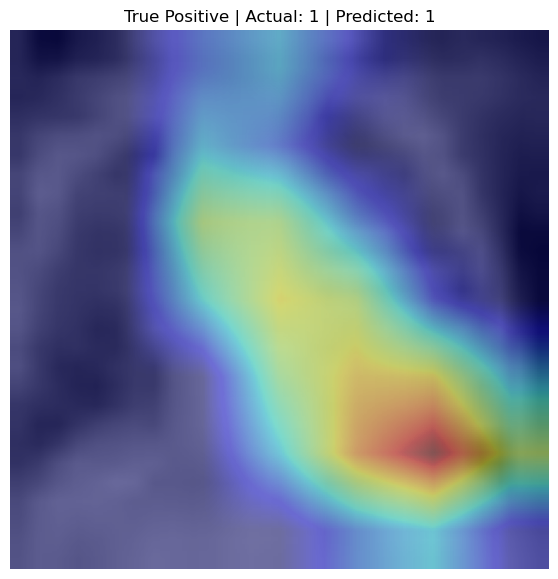

In [20]:
tp_index = true_positive_indices[0]

image, label = test_dataset_resnet[tp_index]

image_batch = image.unsqueeze(0).to(device)

# Generate Grad-CAM for Pneumonia class
cam = generate_gradcam(
    weighted_model,
    image_batch,
    target_class=1
)

plt.figure(figsize=(7, 7))

plt.imshow(
    image.permute(1, 2, 0).numpy()
)

plt.imshow(
    cam,
    cmap="jet",
    alpha=0.4
)

plt.title(
    f"True Positive | "
    f"Actual: {int(label)} | "
    f"Predicted: 1"
)

plt.axis("off")

plt.savefig("../plots/gradcam_for_one_TP.png")

plt.show()

C:\Users\Yash pal\AppData\Local\Temp\ipykernel_9384\2881444135.py:28: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f"Actual: {int(label)} | "


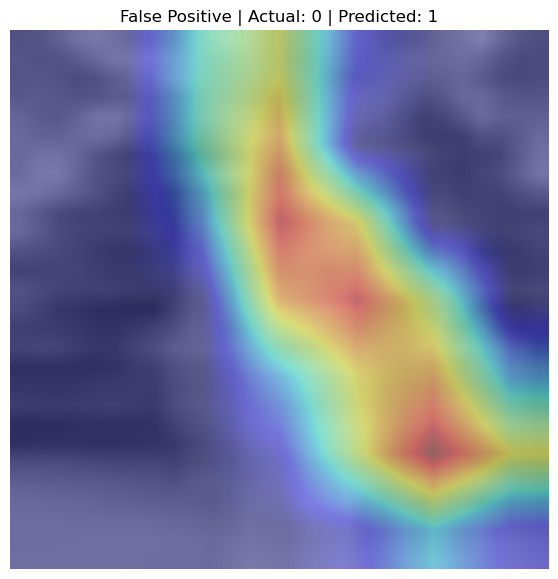

In [21]:
fp_index = false_positive_indices[0]

image, label = test_dataset_resnet[fp_index]

image_batch = image.unsqueeze(0).to(device)

# Explain why model predicted Pneumonia
cam = generate_gradcam(
    weighted_model,
    image_batch,
    target_class=1
)

plt.figure(figsize=(7, 7))

plt.imshow(
    image.permute(1, 2, 0).numpy()
)

plt.imshow(
    cam,
    cmap="jet",
    alpha=0.4
)

plt.title(
    f"False Positive | "
    f"Actual: {int(label)} | "
    f"Predicted: 1"
)

plt.axis("off")

plt.savefig("../plots/gradcam_for_one_FP.png")

plt.show()

In [22]:
import os

gradcam_dir = "../plots/gradcam"

os.makedirs(gradcam_dir, exist_ok=True)

print("Grad-CAM folder ready:", gradcam_dir)

Grad-CAM folder ready: ../results/gradcam


In [23]:
def save_gradcam_visualization(
    model,
    dataset,
    index,
    target_class,
    filename,
    title
):
    
    image, label = dataset[index]

    image_batch = image.unsqueeze(0).to(device)

    # Generate Grad-CAM
    cam = generate_gradcam(
        model,
        image_batch,
        target_class
    )

    # Original image
    original_image = image.permute(
        1, 2, 0
    ).numpy()

    # Plot
    plt.figure(figsize=(7, 7))

    plt.imshow(original_image)

    plt.imshow(
        cam,
        cmap="jet",
        alpha=0.4
    )

    plt.title(title)

    plt.axis("off")

    # Save
    save_path = os.path.join(
        gradcam_dir,
        filename
    )

    plt.savefig(
        save_path,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print("Saved:", save_path)

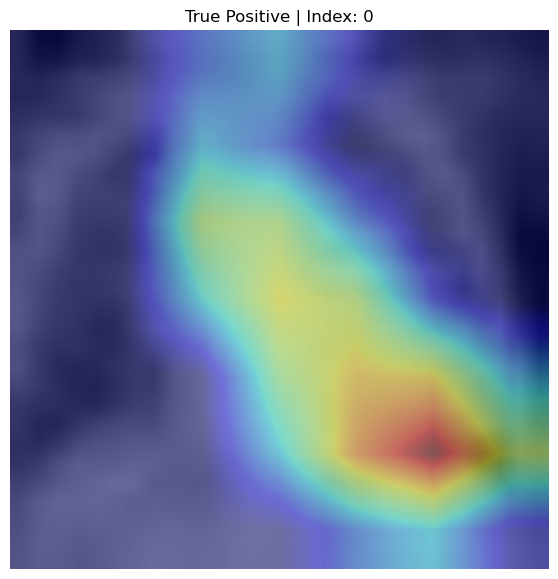

Saved: ../results/gradcam\TP_1.png


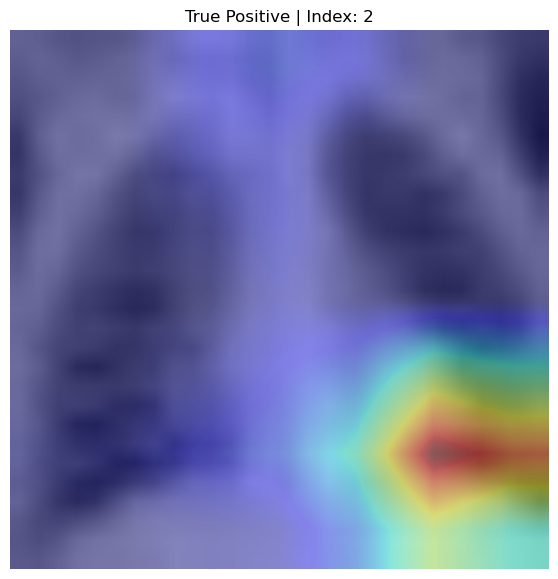

Saved: ../results/gradcam\TP_2.png


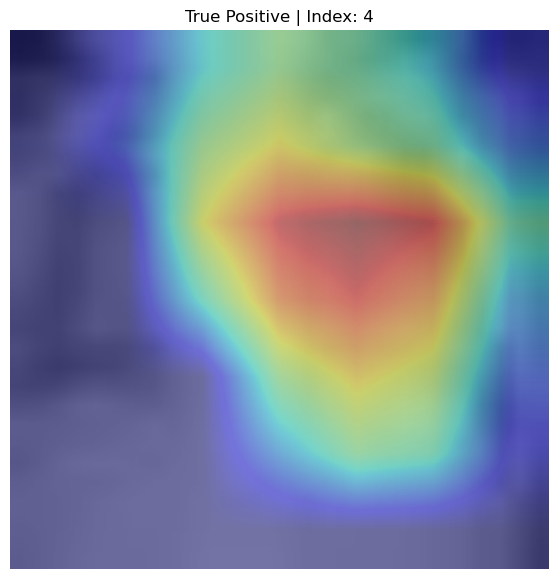

Saved: ../results/gradcam\TP_3.png


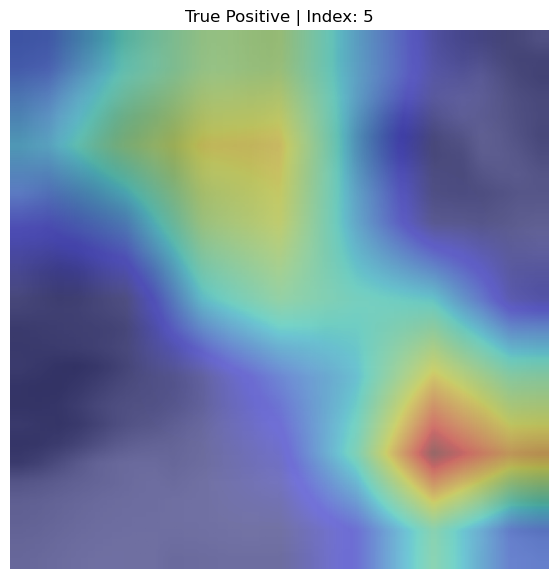

Saved: ../results/gradcam\TP_4.png


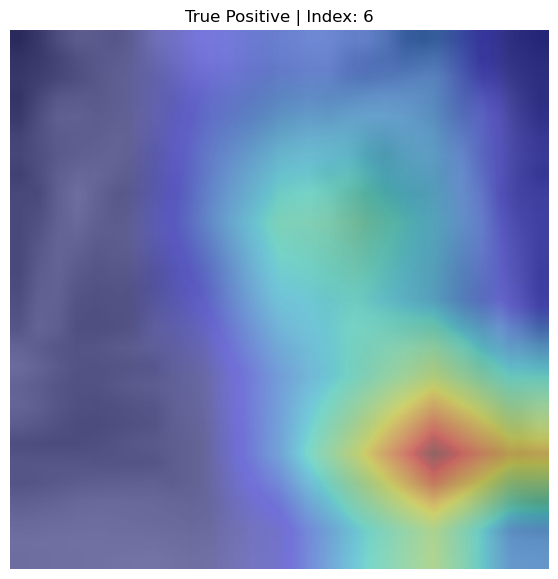

Saved: ../results/gradcam\TP_5.png


In [24]:
for i, index in enumerate(true_positive_indices[:5]):

    save_gradcam_visualization(
        model=weighted_model,
        dataset=test_dataset_resnet,
        index=index,
        target_class=1,
        filename=f"TP_{i+1}.png",
        title=f"True Positive | Index: {index}"
    )

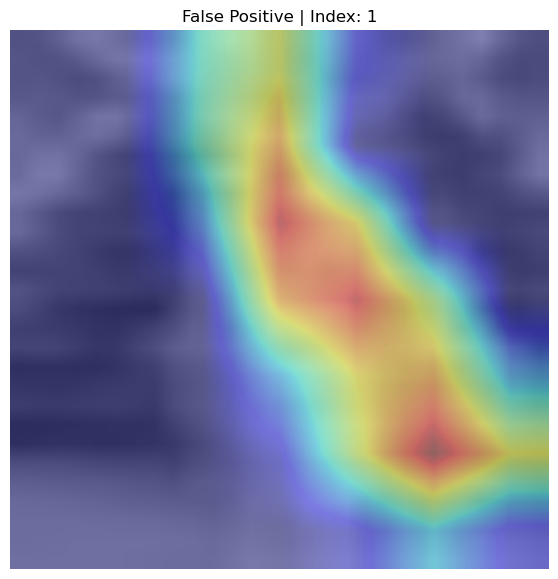

Saved: ../results/gradcam\FP_1.png


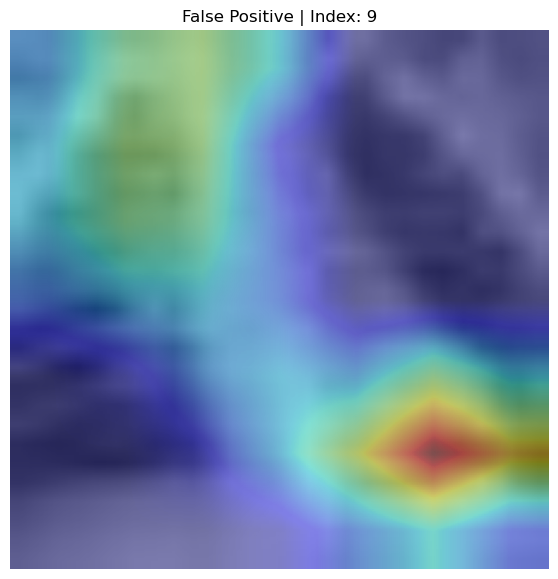

Saved: ../results/gradcam\FP_2.png


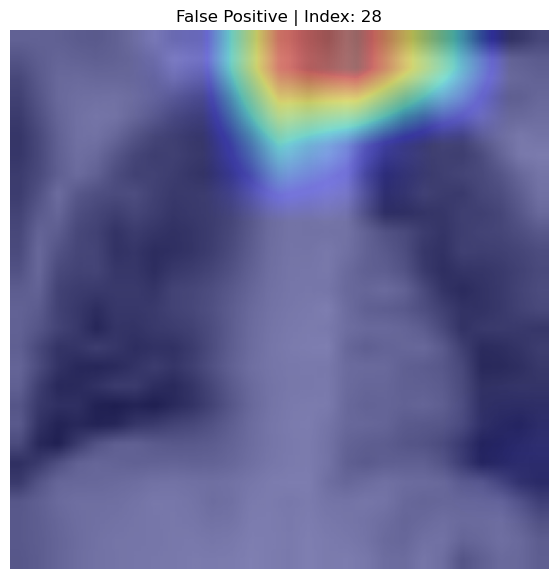

Saved: ../results/gradcam\FP_3.png


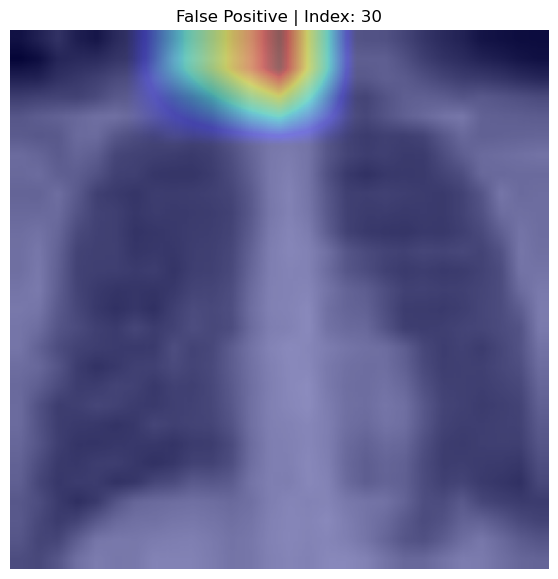

Saved: ../results/gradcam\FP_4.png


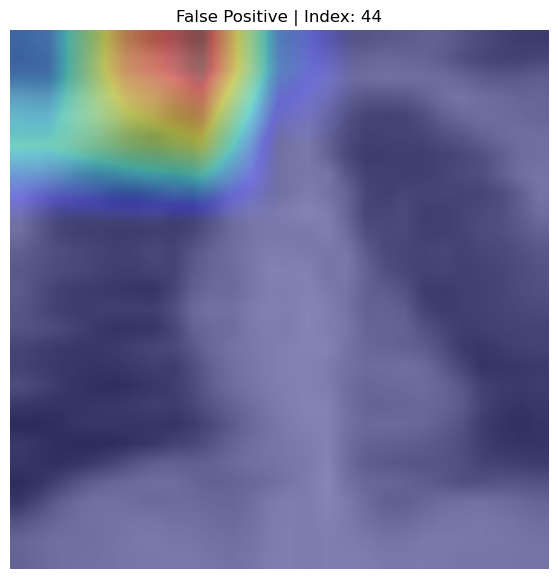

Saved: ../results/gradcam\FP_5.png


In [25]:
for i, index in enumerate(false_positive_indices[:5]):

    save_gradcam_visualization(
        model=weighted_model,
        dataset=test_dataset_resnet,
        index=index,
        target_class=1,
        filename=f"FP_{i+1}.png",
        title=f"False Positive | Index: {index}"
    )